# M2M ladder

The ladder alone: I_FS = 20 µA into the ladder through a PMOS mirror (M1 / M2), both outputs held at V_ref1 by ideal sources, `d[0]` the MSB. All 128 codes are swept at DC; the output current I_D1 is read through H2 (1 kΩ) as `vout`. LSB, DNL and INL are referred to the endpoint line; the best-fit INL is listed for comparison.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sarlib import specs as S
from sarlib.analysis import load_cols, eng, Report

DATA = Path('simulation/ladder_tb.sch')
SP = S.ladder.SPECS
R_H2 = 1e3                       # H2 transresistance: vout = R_H2 * I_D1
rep = Report()

## Code sweep

LSB 151 nA (ideal 156 nA), full scale 19.2 uA; worst DNL at code 64, worst INL at code 64


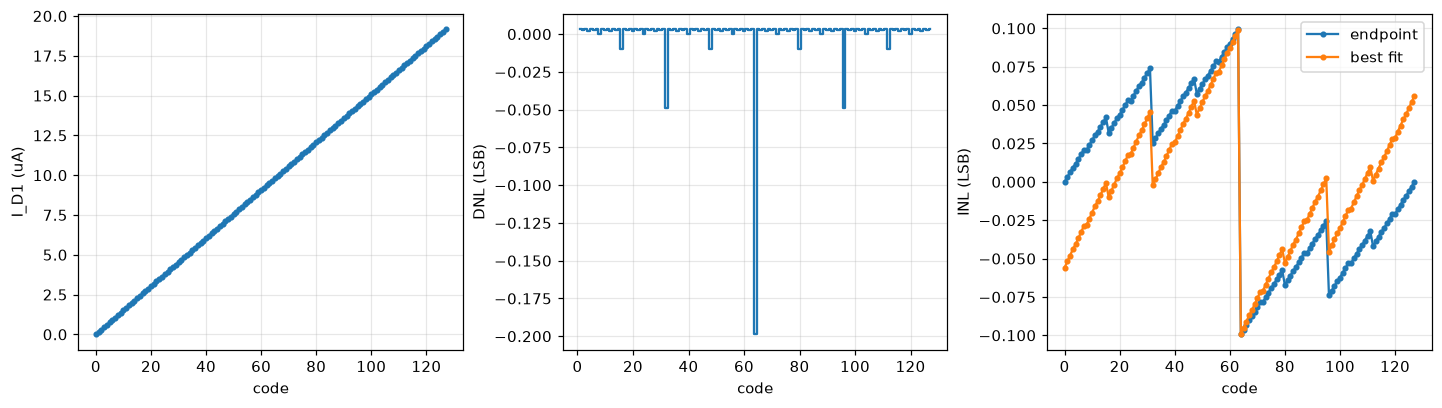

In [2]:
_, w = load_cols(DATA / 'code_sweep.csv', ['code', 'vout'])
code, iout = w['code'].astype(int), w['vout'] / R_H2
assert np.array_equal(code, np.arange(S.NCODE)), f'expected codes 0 ... {S.NCODE - 1}, got {len(code)} rows'

steps = np.diff(iout)
lsb = (iout[-1] - iout[0]) / (S.NCODE - 1)
dnl = steps / lsb - 1
inl = (iout - (iout[0] + code * lsb)) / lsb
fit = np.polyfit(code, iout, 1)
inl_bf = (iout - np.polyval(fit, code)) / fit[0]
missing = np.where(dnl <= -1)[0] + 1
print(f'LSB {eng(lsb, "A")} (ideal {eng(S.I_LSB, "A")}), full scale {eng(iout[-1], "A")}; '
      f'worst DNL at code {np.argmax(np.abs(dnl)) + 1}, worst INL at code {np.argmax(np.abs(inl))}')
rep.limit('INL (endpoint)', np.abs(inl).max(), '{:.3f} LSB', SP['inl_lsb_max'], '<=', 'LSB')
rep.limit('DNL (endpoint)', np.abs(dnl).max(), '{:.3f} LSB', SP['dnl_lsb_max'], '<=', 'LSB')
rep.check('monotonic', 'yes' if (steps > 0).all() else f'no, codes {(np.where(steps <= 0)[0] + 1).tolist()}', 'yes', bool((steps > 0).all()))
rep.check('missing codes', 'none' if missing.size == 0 else str(missing.tolist()), 'none', missing.size == 0)
rep.info('INL (best fit)', f'{np.abs(inl_bf).max():.3f} LSB')
rep.info('LSB', eng(lsb, 'A'), f'ideal {eng(S.I_LSB, "A")}; mirror error included')
rep.info('output at code 0', eng(iout[0], 'A'))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(code, 1e6 * iout, '.-'); ax[0].set(xlabel='code', ylabel='I_D1 (uA)')
ax[1].step(code[1:], dnl, where='mid'); ax[1].set(xlabel='code', ylabel='DNL (LSB)')
ax[2].plot(code, inl, '.-', label='endpoint'); ax[2].plot(code, inl_bf, '.-', label='best fit')
ax[2].set(xlabel='code', ylabel='INL (LSB)'); ax[2].legend()
plt.show()

## Major carries

A binary-weighted split fails first where many bits change at once.

In [3]:
carries = 2 ** np.arange(1, S.N_BITS)
pd.DataFrame({'transition': [f'{c - 1} -> {c}' for c in carries], 'DNL (LSB)': dnl[carries - 1]}).round(4)

,transition,DNL (LSB)
0,1 -> 2,0.0030
1,3 -> 4,0.0024
2,7 -> 8,-0.0001
3,15 -> 16,-0.0099
4,31 -> 32,-0.0487
5,63 -> 64,-0.1988


## Summary

In [4]:
rep.table()

,check,value,spec,result
0,INL (endpoint),0.099 LSB,<= 0.5 LSB,PASS
1,DNL (endpoint),0.199 LSB,<= 0.5 LSB,PASS
2,monotonic,yes,yes,PASS
3,missing codes,none,none,PASS
4,INL (best fit),0.099 LSB,,INFO
5,LSB,151 nA,ideal 156 nA; mirror error included,INFO
6,output at code 0,-1.76 pA,,INFO
